# PC05 — Đánh giá độ bền, lựa chọn phương án và bàn giao nghiên cứu

## Mục tiêu nghiệp vụ
Doanh nghiệp chỉ nên sử dụng nhóm khi hiểu kết quả phụ thuộc vào điều kiện dữ liệu nào. PC05 kiểm tra hai giả định trạng thái, so góc nhìn toàn lịch sử với năm 2022 và tổng hợp đánh đổi giữa các ứng viên.

Phần này không “chữa dữ liệu” để mô hình đẹp hơn. Các kịch bản được công khai là giả định; phạm vi chính vẫn giữ nguyên. Kết luận bàn giao phải nói rõ **được dùng vào việc gì, chưa dùng vào việc gì và cần xác minh gì trước hành động**.

## Chuỗi bằng chứng
PC01 xác nhận phạm vi và tiền → PC02 giải thích đặc trưng → PC03 thực nghiệm mô hình → PC04 đọc ý nghĩa nhóm → PC05 đánh giá điều kiện sử dụng. Mỗi bước có đầu ra và giới hạn riêng; hoàn thành pipeline không đồng nghĩa mọi giả thuyết nghiệp vụ đã được xác minh.


## Bản đồ ký hiệu và nguyên tắc đọc công thức

| Ký hiệu | Ý nghĩa trong notebook |
|---|---|
| c / i | Khách / chỉ số điểm dữ liệu; đọc định nghĩa tại từng công thức |
| o | Một order_id; không phải một dòng sản phẩm |
| E | Tập khách đủ điều kiện RFM delivered |
| T | Mốc31/12/2022 |
| n | Số khách của tập đang phân tích |
| k, Cj | Số cụm và tập khách của cụm j |
| R/F/M | Giá trị thô trên cùng tập đơn đủ điều kiện |
| x, z | Giá trị trước/sau biến đổi theo ngữ cảnh |
| μ, σ | Trung bình/tâm và độ lệch chuẩn, định nghĩa cụ thể cạnh công thức |

Một ký hiệu có thể dùng ở cấp khác trong một công thức khác; mỗi mục đều giải thích phạm vi và mẫu số. Đọc đơn vị, thời gian và trạng thái trước khi so số. Công thức minh họa và kết quả dự án được tách rõ. Các hàm Python giữ tên tiếng Anh để tái sử dụng; nội dung trình bày bằng tiếng Việt.


## Chuẩn bị môi trường và nguồn dữ liệu

Chạy với dữ liệu mô hình đã lưu trong data/model/phan_khuc/v1. Để huấn luyện lại từ PC03, đặt biến môi trường DATATHON_MODEL_RUN thành một tên lượt mới.

In [1]:
from pathlib import Path
import sys
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))
from ham_dung_chung import read_notebook, stable_digest, notebook_prefix

from ham_dung_chung import segmentation_study
Study = segmentation_study().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "v1")
study = Study(ROOT, "PC05")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC05 | Thư mục kết quả: /workspace/scratch/1f9612b45e80/professional/DA_PC/reports/segmentation/professional_v1/PC05


## PC05.1 — Kiểm kê đầu vào và nối với phần nghiệp vụ đã nghiệm thu

**Câu hỏi:** các phần trước thật sự đã hoàn thành trên cùng nguồn chưa?

Manifest completed, hash nguồn và đường dẫn đầu ra là bằng chứng kỹ thuật để tiếp nhận kết quả, không phải thước đo chất lượng học thuật. Bảng dưới kiểm PC01–PC04 và liên hệ NV01.6, NV02, NV06.6, TH01.5 của bản nhóm hiện tại.

NV02 dùng nhiều phạm vi mô tả khách, trong đó có tập mọi trạng thái; phân cụm chính dùng delivered. Không thay số khách của NV02 bằng số khách RFM hoặc coi NV02 đã phân cụm. Tương tự, thông tin danh mục và mã khuyến mãi giúp đặt câu hỏi về profile, không tự xác nhận nguyên nhân hoặc hiệu quả marketing.

**Quy tắc bàn giao:** chỉ so trực tiếp các số khi trùng đơn vị quan sát, mẫu khách/đơn, thời gian, trạng thái và công thức. Nếu một điều khác, phải ghi rõ là bổ sung ngữ cảnh hoặc giả thuyết, không gọi là đối soát số học.

Các file nghiệp vụ của nhóm được giữ nguyên. Lần chạy này không chứng nhận lại mọi kết luận Bài toán1 và không sửa các hồ sơ hash lịch sử để báo đạt.


In [2]:
model_manifest=study.use_model(MODEL_LABEL)
rows = []
for number in range(1, 5):
    part = f"PC{number:02}"
    path = next(
        (ROOT / "notebook/05_phan_khuc_khach_hang").glob(f"{part}_*.ipynb")
    )
    cells = read_notebook(path)["cells"]
    saved = [cell for cell in cells if cell["cell_type"] == "code"]
    rows.append({
        "Phần": part,
        "Notebook": path.name,
        "Ô code đã lưu kết quả": sum(c.get("execution_count") is not None for c in saved),
    })
study.table("input_inventory", "Kiểm kê notebook PC01–PC04", pd.DataFrame(rows))
upstream=[]
for name,marker,usage,limit in [
 ('NV01_phan_tich_ban_hang.ipynb','NV01.6','Đối chiếu cơ cấu danh mục/Net delivered trong PC04','Không coi lượng/Net là lợi nhuận'),
 ('NV02_phan_tich_khach_hang.ipynb','NV02','Kế thừa câu hỏi khách hàng; phân biệt90246 khách có đơn với85115 khách RFM','Không đổi mẫu số NV02 hoặc gọi đó là phân cụm đã hoàn thành'),
 ('NV06_phan_tich_khuyen_mai_marketing.ipynb','NV06.6','Kế thừa giới hạn mã/khuyến mãi khi đọc hành vi nhóm','Không quy khác biệt mô tả thành uplift/ROI'),
 ('TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb','TH01.5','Dẫn tới tổng hợp nghiệp vụ hiện hành của bản mới','Không đóng các vấn đề thiếu chứng từ hoặc thay kết luận Bài toán1')]:
 path=ROOT/'notebook/04_phan_tich_kinh_doanh'/name;doc=read_notebook(path);require(any(marker in ''.join(cell.get('source',[])) for cell in doc['cells']),'Thiếu phần hiện hành '+marker)
 upstream.append({'Nguồn bản mới':name,'Phần hiện hành':marker,'Kế thừa cho phân cụm':usage,'Giới hạn giữ nguyên':limit})
study.table('upstream_business_handoff','Liên hệ Bài toán2 với các phần cập nhật của nhóm',pd.DataFrame(upstream))
study.note('Các notebookkinhdoanh được đọc như tài liệu/nguồn phân tích đã bàn giao, không tái chạy hoặc sửa ở đây. Lượt mô hình đang đọc được ghi ở ô thiết lập. Bộ đặc trưng và nhãn lưu cùng dữ liệu mô hình.')

,part,state,baseline,model_run,tables,figures,commentary_blocks,raw_unchanged,baseline_manifest_sha256
0,PC01,completed,v1,v1,9,2,9,True,95948f0feb349f3091a85baa3a31a557ae652fa403e35d...
1,PC02,completed,v1,v1,13,6,11,True,95948f0feb349f3091a85baa3a31a557ae652fa403e35d...
2,PC03,completed,v1,professional_model_v1,14,1,9,True,95948f0feb349f3091a85baa3a31a557ae652fa403e35d...
3,PC04,completed,v1,professional_model_v1,18,3,16,True,95948f0feb349f3091a85baa3a31a557ae652fa403e35d...


,Nguồn bản mới,Phần hiện hành,Kế thừa cho phân cụm,Giới hạn giữ nguyên
0,NV01_phan_tich_ban_hang.ipynb,NV01.6,Đối chiếu cơ cấu danh mục/Net delivered trong ...,Không coi lượng/Net là lợi nhuận
1,NV02_phan_tich_khach_hang.ipynb,NV02,Kế thừa câu hỏi khách hàng; phân biệt90246 khá...,Không đổi mẫu số NV02 hoặc gọi đó là phân cụm ...
2,NV06_phan_tich_khuyen_mai_marketing.ipynb,NV06.6,Kế thừa giới hạn mã/khuyến mãi khi đọc hành vi...,Không quy khác biệt mô tả thành uplift/ROI
3,TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb,TH01.5,Dẫn tới tổng hợp nghiệp vụ hiện hành của bản mới,Không đóng các vấn đề thiếu chứng từ hoặc thay...


Các notebookkinhdoanh được đọc như tài liệu/nguồn phân tích đã bàn giao, không tái chạy hoặc sửa ở đây. Mô hình phân cụm được tính từ common/raw của chínhZIP mới, không từ output mô hình hôm trước.

## PC05.2 — Độ nhạy trạng thái với scaler và tâm giữ cố định

**Câu hỏi:** nếu cách hiểu bằng chứng shipment khác đi, nhóm của cùng khách có thay đổi mạnh không?

Giữ mô hình chính $g_0$ và scaler chính. Tính lại đặc trưng ở mỗi kịch bản, rồi so trên tập khách chung $E_0\cap E_s$:

$$ChangeRate_s=\frac{\sum_{c\in E_0\cap E_s}\mathbf{1}[g_0(x_c^{(0)})\ne g_0(x_c^{(s)})]}{|E_0\cap E_s|}.$$

$E_0$ là tập chính, $E_s$ là tập kịch bản; $x_c^{(0)}$ và $x_c^{(s)}$ là RFM của cùng khách theo hai quy tắc. Nhãn dùng cùng center ID, nên so trực tiếp được. Tách số khách thêm/bớt khỏi tỷ lệ trên khách chung.

- **Kịch bản1:** bỏ delivered thiếu shipment. Kiểm tác động khi yêu cầu bằng chứng bảng con chặt hơn.
- **Kịch bản2:** giả định thêm shipped có delivery_date trước hoặc bằng mốc chốt. Kiểm một cách hiểu khác, chưa xác nhận đó là giao thực tế.

**Ví dụ:** tập chính100khách, kịch bản còn90khách chung và3người đổi nhãn thì ChangeRate=3/90=3,33%, không3/100. Mười khách mất điều kiện phải báo riêng, không coi đã đổi sang cụm khác.

**Giới hạn:** đây là độ nhạy đặc trưng dưới mô hình cố định. Nếu fit lại scaler/tâm thì cả biểu diễn và ranh giới thay đổi, cần ARI/ghép phân hoạch; không dùng phép đếm nhãn trực tiếp như trên. Ít đổi nhóm chưa chứng minh trạng thái nguồn đúng, chỉ cho biết tác động của hai kịch bản đã thử.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [3]:
# VÍ DỤ GIẢ LẬP: báo khách chung và thay đổi nhãn riêng biệt.
toy_base=np.r_[np.zeros(45,dtype=int),np.ones(45,dtype=int)];toy_case=toy_base.copy();toy_case[:3]=1
toy_changed=int((toy_base!=toy_case).sum());toy_rate=toy_changed/len(toy_base);assert np.isclose(toy_rate,3/90)
study.table('VD10_sensitivity','Ví dụ giả lập — mẫu số độ nhạy',pd.DataFrame([{'Khách tập chính':100,'Khách chung':90,'Khách mất điều kiện':10,'Khách chung đổi nhãn':toy_changed,'Tỷ lệ đúng trên khách chung':toy_rate,'Tỷ lệ3/100 không đúng mục tiêu':toy_changed/100}]))

Out[3]: 
   Khách tập chính  Khách chung  Khách mất điều kiện  Khách chung đổi nhãn  \
0              100           90                   10                     3   

   Tỷ lệ đúng trên khách chung  Tỷ lệ3/100 không đúng mục tiêu  
0                     0.033333                            0.03  


,Khách tập chính,Khách chung,Khách mất điều kiện,Khách chung đổi nhãn,Tỷ lệ đúng trên khách chung,Tỷ lệ3/100 không đúng mục tiêu
0,100,90,10,3,0.033333,0.03


,scenario,Số đơn,Số khách,common_customers,removed_customers,added_customers,customers_with_changed_RFM,ari_frozen_model,share_changed_frozen_labels
0,remove_delivered_without_shipment,516192,85095,85095,20,0,493,0.996302,0.001105
1,hypothesis_add_shipped_with_delivery_date,530478,85735,85115,0,620,11169,0.961403,0.012477


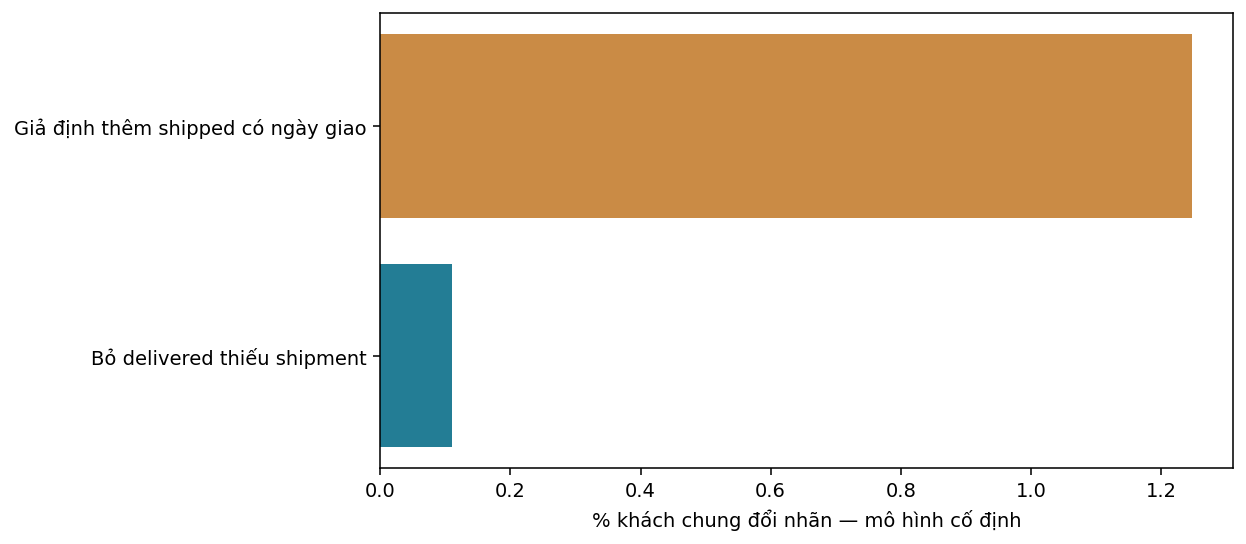

remove_delivered_without_shipment: 85,095 khách chung, thêm 0, bớt 20; 493 khách thay RFM; 0.11% đổi nhãn; ARI=0.9963. Ít đổi nhóm không chứng minh trạng thái đúng.

hypothesis_add_shipped_with_delivery_date: 85,115 khách chung, thêm 620, bớt 0; 11,169 khách thay RFM; 1.25% đổi nhãn; ARI=0.9614. Ít đổi nhóm không chứng minh trạng thái đúng.

In [4]:
s=pd.read_csv(study.modelbase/'status_sensitivity.csv')
study.table('status_sensitivity','Hai kịch bản độ nhạy',s.drop(columns='method'))
fig,ax=plt.subplots(figsize=(9,4));ax.barh(['Bỏ delivered thiếu shipment','Giả định thêm shipped có ngày giao'],s.share_changed_frozen_labels*100,color=['#237d95','#ca8b45']);ax.set(xlabel='% khách chung đổi nhãn — mô hình cố định');study.fig('status_sensitivity','Tỷ lệ đổi nhãn trên khách chung',fig)
for row in s.itertuples():study.note(f'{row.scenario}: {row.common_customers:,} khách chung, thêm {row.added_customers:,}, bớt {row.removed_customers:,}; {row.customers_with_changed_RFM:,} khách thay RFM; {row.share_changed_frozen_labels:.2%} đổi nhãn; ARI={row.ari_frozen_model:.4f}. Ít đổi nhóm không chứng minh trạng thái đúng.')

## PC05.3 — Cửa sổ thời gian: tích lũy khác hoạt động gần đây

**Câu hỏi:** mô hình toàn lịch sử có phản ánh hành vi gần cuối kỳ không?

Toàn lịch sử đếm mọi đơn đủ điều kiện đến T. Với cửa sổ đúng L ngày có cả ngày T, quy tắc lọc là:

$$T-(L-1)\leq t_o\leq T.$$

Với năm2022, dùng 01/01/2022–31/12/2022. Khách có delivered năm2022 có cùng lần đặt delivered cuối so với toàn lịch sử nên R trên khách chung bằng nhau; F/M toàn lịch sử không nhỏ hơn F/M năm2022.

Đối tượng hai phạm vi có thể khác. Tỷ trọng khách một đơn thay đổi vừa do mất đơn cũ, vừa do khách không có đơn gần đây không còn trong tập. Không chỉ nhìn tổng khách và kết luận cách nào “chính xác hơn”.

Bước dưới chỉ tính lại **phạm vi và đặc trưng**, chưa huấn luyện mô hình2022 trong bộ nghiên cứu này. Muốn so mô hình theo cửa sổ cần thêm một thí nghiệm riêng, báo tập khách chung, scaler/biến đổi và cách đánh giá tương ứng.

**Quyết định:** dùng lịch sử làm góc nhìn đóng góp tích lũy, giữ phạm vi2022 làm đầu vào nghiên cứu độ nhạy thời gian. F/M tích lũy chưa điều chỉnh cơ hội quan sát và mức tiền qua nhiều năm; không gọi là tiềm năng tương lai.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [5]:
# VÍ DỤ GIẢ LẬP: cửa sổ có cả hai đầu.
toy_T=pd.Timestamp('2022-12-31');toy_L=5;toy_start=toy_T-pd.Timedelta(days=toy_L-1);toy_dates=pd.date_range(toy_start,toy_T,freq='D');assert len(toy_dates)==toy_L
study.table('VD11_window','Ví dụ giả lập — cửa sổ5ngày kết thúc31/12',pd.DataFrame({'Ngày được chọn':toy_dates.date}))

Out[5]: 
  Ngày được chọn
0     2022-12-27
1     2022-12-28
2     2022-12-29
3     2022-12-30
4     2022-12-31


,Ngày được chọn
0,2022-12-27
1,2022-12-28
2,2022-12-29
3,2022-12-30
4,2022-12-31


In [6]:
o=study.orders();delivered=o.loc[o.order_status.eq('delivered') & o.order_date.le(CUTOFF)];recent=rfm(delivered.loc[delivered.order_date.ge('2022-01-01')])
rows=[]
for name,f in [('Toàn lịch sử',study.f),('Năm2022',recent)]:rows.append({'Phạm vi':name,'Số khách':len(f),'Tổng đơn':int(f.Frequency.sum()),'Tỷ trọng một đơn':f.Frequency.eq(1).mean(),'R trung vị':f.Recency.median(),'F trung vị':f.Frequency.median(),'M trung vị':f.Monetary.astype(float).median()})
study.table('window_feature_comparison','Đối chiếu phạm vi/đặc trưng — chưa so mô hình',pd.DataFrame(rows))
common=recent.merge(study.f,on='customer_id',suffixes=('_2022','_history'),validate='one_to_one')
require(common.Recency_2022.eq(common.Recency_history).all(),'R khách chung phải bằng nhau')
require(common.Frequency_history.ge(common.Frequency_2022).all(),'F lịch sử không được nhỏ hơn')
study.note('Cửa sổ năm2022 mô tả hoạt động gần cuối; toàn lịch sử mô tả tích lũy. Chưa thực nghiệm mô hình cửa sổ này trong PC01–PC05; đây là đầu vào nghiên cứu tiếp, không tự thay kết quả chính.')

,Phạm vi,Số khách,Tổng đơn,Tỷ trọng một đơn,R trung vị,F trung vị,M trung vị
0,Toàn lịch sử,85115,516716,0.268378,1142.0,3.0,79730.85
1,Năm2022,20389,27688,0.747560,185.0,1.0,30099.45


Cửa sổ năm2022 mô tả hoạt động gần cuối; toàn lịch sử mô tả tích lũy. Chưa thực nghiệm mô hình cửa sổ này trong PC01–PC05; đây là đầu vào nghiên cứu tiếp, không tự thay kết quả chính.

## PC05.4 — Lựa chọn phương án cho mục tiêu nghiệp vụ hiện tại

**Câu hỏi:** vì sao đề xuất một k khi các chỉ số không cùng chọn nó?

Không có trọng số nghiệp vụ hoặc nhãn đúng để chứng minh nghiệm tối ưu tuyệt đối. Quyết định hiện tại là khuyến nghị cho **báo cáo mô tả phân khúc**, dựa trên chuỗi bằng chứng:

1. Phạm vi/tiền hợp lệ theo chính sách đã chốt.
2. Cấu hình có quy mô cụm đủ đọc và chỉ số nội bộ thuận lợi.
3. Phân hoạch ổn định trước các seed đã thử.
4. Hồ sơ cho thấy mức khác biệt có thể giải thích bằng R/F/M và hành vi.
5. Độ nhạy trạng thái được công bố; không che khách thêm/bớt.
6. Độ chi tiết thêm so với k2/k4 có ý nghĩa cho mục tiêu trình bày.

Nếu k2 có Silhouette cao hơn nhưng k3 có DB thấp hơn và một nhóm trung gian hữu ích, phải viết rõ đánh đổi đó. Nếu chưa có mục tiêu riêng cho nhóm đuôi được k4 tách, không lấy số cụm lớn hơn làm dấu hiệu bài làm tốt hơn.

**Mức quyết định:** đề xuất kỹ thuật/phân tích đã có bằng chứng; chưa là quyết định phân bổ ngân sách hoặc triển khai chăm sóc. Thay đổi mục tiêu doanh nghiệp có thể làm k2 hoặc k4 phù hợp hơn mà không phủ nhận kết quả hiện tại.


In [7]:
grid=pd.read_csv(study.modelbase/'experiment_grid.csv');variant=model_manifest['selected']['variant'];t=grid.loc[(grid.variant==variant)&grid.k.isin([2,3,4])].copy()
t['Đánh đổi']=['Ít nhóm, dễ dùng; có thể gộp các mức hoạt động' if k==2 else 'Thêm một góc phân biệt; cần hồ sơ PC04' if k==3 else 'Chi tiết hơn; cân nhắc tách đuôi và độ phức tạp' for k in t.k]
study.table('decision_candidates','Ma trận phương án cùng phép biến đổi',t)
k=model_manifest['selected']['k'];study.note(f'Khuyến nghị cho mục tiêu mô tả hiện tại: {variant}, k={k}. Có căn cứ từ chỉ số, seed và hồ sơ; chưa chứng minh tối ưu kinh doanh. Nếu mục tiêu thay đổi, k2/k4 vẫn là ứng viên hợp lệ. Không dùng tổng hạng thay xác nhận nghiệp vụ.')
selected=t.loc[t.k.eq(k)].iloc[0];r2=t.loc[t.k.eq(2)].iloc[0];r4=t.loc[t.k.eq(4)].iloc[0]
study.note(f'Đánh đổi định lượng: k2 có Silhouette {r2.silhouette_sample:.4f} cao hơn k3 {selected.silhouette_sample:.4f}, nhưng DB k3={selected.davies_bouldin_full:.4f} thấp hơn k2={r2.davies_bouldin_full:.4f}. k4 có Silhouette {r4.silhouette_sample:.4f} và cụm nhỏ nhất {r4.min_cluster_share:.2%}. PC04 cho thấy k3 phân biệt nhóm lâu chưa mua/ít đơn, nhóm trung gian và nhóm mua nhiều/Net cao hơn; k4 thêm chi tiết đuôi chưa có mục tiêu riêng. Vì vậy giữ k3 cho báo cáo mô tả, không gọi tốt nhất cho mọi mục tiêu.')

,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds,Đánh đổi
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.326729,"Ít nhóm, dễ dùng; có thể gộp các mức hoạt động"
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.284777,Thêm một góc phân biệt; cần hồ sơ PC04
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,0.314349,Chi tiết hơn; cân nhắc tách đuôi và độ phức tạp


Khuyến nghị cho mục tiêu mô tả hiện tại: TN1, k=3. Có căn cứ từ chỉ số, seed và hồ sơ; chưa chứng minh tối ưu kinh doanh. Nếu mục tiêu thay đổi, k2/k4 vẫn là ứng viên hợp lệ. Không dùng tổng hạng thay xác nhận nghiệp vụ.

Đánh đổi định lượng: k2 có Silhouette 0.5171 cao hơn k3 0.4589, nhưng DB k3=0.7433 thấp hơn k2=0.7831. k4 có Silhouette 0.4416 và cụm nhỏ nhất 4.42%. PC04 cho thấy k3 phân biệt nhóm lâu chưa mua/ít đơn, nhóm trung gian và nhóm mua nhiều/Net cao hơn; k4 thêm chi tiết đuôi chưa có mục tiêu riêng. Vì vậy giữ k3 cho báo cáo mô tả, không gọi tốt nhất cho mọi mục tiêu.

## PC05.5 — Giới hạn dữ liệu, phương pháp và việc chưa làm

Một báo cáo có trách nhiệm phải phân biệt ba nhóm: vấn đề nguồn chưa rõ, giới hạn thiết kế và công việc chưa thực hiện. Không gọi tất cả là lỗi dữ liệu cần sửa.

| Nhóm | Câu hỏi chưa trả lời | Hệ quả khi sử dụng |
|---|---|---|
| Trạng thái/thời gian | Nhãn đã được biết ở thời điểm nào? Ngày giao thực hay dự kiến? | Chưa backtest as-of; không tự sửa status |
| Tiền | Đã quyết toán, thuế/phí và chi hoàn ra sao? | M chưa là thực thu hoặc lợi nhuận |
| Cơ hội quan sát | Khách được quan sát trong bao lâu thực sự? | F/M tích lũy chưa chứng minh trung thành/CLV |
| Phương pháp | K-Means giả định khoảng cách và nhạy biểu diễn | Cần đọc đối thủ và độ nhạy, không gọi nhãn là chân lý |
| Đánh giá | Mẫu dùng chọn cấu hình, chưa holdout/ổn định thời gian | Không gọi chỉ số nội bộ là accuracy dự báo |
| Hiệu quả | Chăm sóc theo nhóm có cải thiện kết quả không? | Hành động mới là giả thuyết cần thử nghiệm |

Bốn kiểm thử hồi quy cũ chưa đạt đã được đối chứng trên ZIP gốc; các vấn đề hash/provenance và memorybyte phụ thuộc môi trường phải được công bố. Việc phần phân cụm chạy được không biến toàn repository thành all-green.

**Điều kiện trước hành động:** xác minh định nghĩa quan trọng với nghiệp vụ; xác định người dùng kết quả, mẫu số KPI và thiết kế đánh giá phù hợp; theo dõi dữ liệu/nhóm khi nguồn cập nhật. Những điều này không tự hoàn thành bởi một bảng nhãn.


In [8]:
limits=pd.DataFrame([
{'Nhóm':'Nguồn','Giới hạn':'Không lịch sử status/updated_at/extraction time','Hệ quả':'Không tái dựng chuyển trạng thái/backtest as-of','Cần thêm':'Log sự kiện hoặc từ điển nghiệp vụ'},
{'Nhóm':'Nguồn','Giới hạn':'Payment/delivery_date chưa xác nhận ngữ nghĩa','Hệ quả':'Không tự sửa status, không gọi M là thực thu','Cần thêm':'Định nghĩa và chứng từ'},
{'Nhóm':'Phương pháp','Giới hạn':'F/M tích lũy chịu cơ hội/thời gian quan sát','Hệ quả':'Không đồng nhất với trung thành/tiềm năng','Cần thêm':'Cohort/cửa sổ và lịch sử hợp lệ'},
{'Nhóm':'Phương pháp','Giới hạn':'Metrics dùng chọn mô hình, không holdout','Hệ quả':'Không gọi là độ chính xác dự báo','Cần thêm':'Ổn định theo thời gian/đánh giá sử dụng'},
{'Nhóm':'Chưa làm','Giới hạn':'Chưa DBSCAN hoặc RFM mở rộng','Hệ quả':'Baseline chưa bao quát mọi thuật toán/đặc trưng','Cần thêm':'Thí nghiệm riêng nếu có lý do'},
{'Nhóm':'Chưa làm','Giới hạn':'Chưa kiểm hiệu quả chăm sóc/ưu đãi','Hệ quả':'Hành động mới là giả thuyết','Cần thêm':'Thẩm định và thử nghiệm có đối chứng'}])
study.table('limitations','Ma trận giới hạn và điều kiện',limits)
study.note('Kết quả sẵn sàng cho báo cáo phân cụm mô tả có giới hạn. Chưa sẵn sàng gọi churn/VIP/CLV hoặc triển khai quyết định kinh doanh tự động.')

,Nhóm,Giới hạn,Hệ quả,Cần thêm
0,Nguồn,Không lịch sử status/updated_at/extraction time,Không tái dựng chuyển trạng thái/backtest as-of,Log sự kiện hoặc từ điển nghiệp vụ
1,Nguồn,Payment/delivery_date chưa xác nhận ngữ nghĩa,"Không tự sửa status, không gọi M là thực thu",Định nghĩa và chứng từ
2,Phương pháp,F/M tích lũy chịu cơ hội/thời gian quan sát,Không đồng nhất với trung thành/tiềm năng,Cohort/cửa sổ và lịch sử hợp lệ
3,Phương pháp,"Metrics dùng chọn mô hình, không holdout",Không gọi là độ chính xác dự báo,Ổn định theo thời gian/đánh giá sử dụng
4,Chưa làm,Chưa DBSCAN hoặc RFM mở rộng,Baseline chưa bao quát mọi thuật toán/đặc trưng,Thí nghiệm riêng nếu có lý do
5,Chưa làm,Chưa kiểm hiệu quả chăm sóc/ưu đãi,Hành động mới là giả thuyết,Thẩm định và thử nghiệm có đối chứng


Kết quả sẵn sàng cho báo cáo phân cụm mô tả có giới hạn. Chưa sẵn sàng gọi churn/VIP/CLV hoặc triển khai quyết định kinh doanh tự động.

## PC05.6 — Kết luận điều hành và bộ bàn giao có thể tái lập

Một kết luận cuối nên trả lời: **đã phân nhóm ai, theo cách nào, quan sát được gì, vì sao chọn phương án, giới hạn nào còn mở và bước tiếp theo là gì**. Không viết lại toàn bộ bảng như kết luận, nhưng mỗi con số nêu ra phải truy được về bảng hoặc biến nguồn.

Bộ bàn giao gồm:

- Hợp đồng phạm vi và bảng khách ngoài tập có lý do.
- RFM gốc giữ tiền chính xác, hành vi bổ trợ và cờ dữ liệu.
- Thiết kế/cấu hình, kết quả mọi ứng viên và sample ID.
- Scaler, tâm và mapping nhãn; hồ sơ nhóm trên thang gốc.
- Bằng chứng seed, đối chứng mẫu và độ nhạy trạng thái.
- Phát hiện, giả thuyết hành động và điều kiện sử dụng.
- Kiểm chứng bảo toàn nguồn, ví dụ công thức và hướng dẫn chạy lại.

Các notebook là sản phẩm phân tích chính, theo cách nhóm triển khai Bài toán1; module Python giữ phép tính dùng lại, không thay phần giải thích. Báo cáo HTML là bản đọc thuận tiện của cùng nội dung, có công thức hiển thị được khi ngoại tuyến.

**Hướng phát triển có kiểm soát:** thí nghiệm RFM mở rộng với ít biến không trùng thông tin; kiểm cửa sổ thời gian/cohort khi đủ định nghĩa; bổ sung DBSCAN nếu có câu hỏi về mật độ/noise; đánh giá hành động bằng thiết kế phù hợp. Không liệt kê các hướng đó như thành phần đã hoàn thành.


In [9]:
profiles=pd.read_csv(study.modelbase/'cluster_profiles.csv')
study.table('final_profiles','Hồ sơ được chọn để bàn giao',profiles)
for row in profiles.itertuples():study.note(f'Nhóm {row.cluster}: {row.customers:,} khách ({row.customer_share:.2%}), R trung vị {row.Recency_median:.0f} ngày, F {row.Frequency_median:.0f} đơn, M {row.Monetary_median:,.2f} ĐVT nguồn; đóng góp {row.Monetary_share:.2%} Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.')
study.note('Tổng hợp: thiết kế đã kiểm phạm vi/tiền, phân bố/ngoại lệ, 14 cấu hình, seed, đối chứng mẫu, hồ sơ trong nhóm và độ nhạy trạng thái. Không xóa bất thường để làm metrics đẹp. Giữ RFM delivered làm chính; mọi trạng thái bổ trợ diễn giải. Mở rộng cửa sổ/đặc trưng là bước nghiên cứu tiếp có kiểm soát.')

,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


Nhóm 0: 34,498 khách (40.53%), R trung vị 2307 ngày, F 1 đơn, M 29,651.97 ĐVT nguồn; đóng góp 11.46% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Nhóm 1: 40,342 khách (47.40%), R trung vị 598 ngày, F 5 đơn, M 124,473.99 ĐVT nguồn; đóng góp 44.85% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Nhóm 2: 10,275 khách (12.07%), R trung vị 244 ngày, F 19 đơn, M 477,244.08 ĐVT nguồn; đóng góp 43.68% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Tổng hợp: thiết kế đã kiểm phạm vi/tiền, phân bố/ngoại lệ, 14 cấu hình, seed, đối chứng mẫu, hồ sơ trong nhóm và độ nhạy trạng thái. Không xóa bất thường để làm metrics đẹp. Giữ RFM delivered làm chính; mọi trạng thái bổ trợ diễn giải. Mở rộng cửa sổ/đặc trưng là bước nghiên cứu tiếp có kiểm soát.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [10]:
study.note("### Kết luận điều hành và mức sẵn sàng sử dụng")
study.note(f'Nghiên cứu giữ RFM delivered toàn lịch sử làm phương án chính, đề xuất {study.modelmanifest["selected"]["variant"]}/k={study.modelmanifest["selected"]["k"]} cho báo cáo mô tả. Có đối thủ, hồ sơ, kiểm seed và độ nhạy để người đọc đánh giá; chưa chứng minh hiệu quả phân bổ ngân sách hay giá trị khách tương lai. Bước trước hành động là xác minh định nghĩa trọng yếu, đặt mục tiêu và chọn KPI có mẫu số rõ. Bốn lỗi hồi quy cũ đã có đối chứng vẫn phải được công bố, không coi completed của phân cụm là mọi test toàn dự án đều đạt.')

### Kết luận điều hành và mức sẵn sàng sử dụng

Nghiên cứu giữ RFM delivered toàn lịch sử làm phương án chính, đề xuất TN1/k=3 cho báo cáo mô tả. Có đối thủ, hồ sơ, kiểm seed và độ nhạy để người đọc đánh giá; chưa chứng minh hiệu quả phân bổ ngân sách hay giá trị khách tương lai. Bước trước hành động là xác minh định nghĩa trọng yếu, đặt mục tiêu và chọn KPI có mẫu số rõ. Bốn lỗi hồi quy cũ đã có đối chứng vẫn phải được công bố, không coi completed của phân cụm là mọi test toàn dự án đều đạt.

## Kiểm chứng và lưu sản phẩm phân tích

Đối chiếu hash nguồn, lưu bảng/hình và manifest. Công thức, ví dụ, kết quả và diễn giải đều nằm trong notebook; báo cáo HTML được xuất từ chính nội dung này.

In [11]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC05', 'state': 'completed', 'baseline': 'v1', 'model_run': 'professional_model_v1', 'tables': 9, 'figures': 1, 'commentary_blocks': 13, 'raw_unchanged': True, 'baseline_manifest_sha256': '95948f0feb349f3091a85baa3a31a557ae652fa403e35d1be425a915294c3fef'}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
